# McCabe-Thiele Distillation: Predicting Stage Count & Feed Stage with Linear Regression

**Goal:** predict two things about a binary distillation column from its design parameters:
1. **Number of theoretical stages**
2. **Feed stage location**

**How:** generate synthetic data with my own McCabe-Thiele code, then train a linear regression baseline.

**Notebook map**
1. Imports
2. McCabe-Thiele functions
3. Generate the data (5000 samples)
4. Explore the data
5. Feature engineering
6. Train/test split
7. Model 1: number of stages
8. Model 2: feed stage
9. Results summary
10. Error inspection
11. What I learned / next steps

## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

## 2. McCabe-Thiele functions

Building blocks of the McCabe-Thiele diagram:
- **Equilibrium curve** (and its inverse), from relative volatility `alpha`
- **Rectifying line**, from reflux ratio `R` and distillate composition `xD`
- **Stripping line**, from bottoms composition `xB` to the feed/rectifying intersection
- **Minimum reflux ratio**, from the pinch point on the equilibrium curve

In [2]:
def equilibrium_curve(x, alpha):
    """y-x equilibrium relation for a binary mixture given relative volatility alpha."""
    y = alpha * x / (1 + (alpha - 1) * x)
    return y

def x_equilibrium_curve(y, alpha):
    """Inverse of the equilibrium curve: solve for x given y."""
    x = y / (alpha - y * (alpha - 1))
    return x

def rectifying_line(x, R, xD):
    """Operating line above the feed stage."""
    y = (R / (1 + R)) * x + xD / (R + 1)
    return y

def stripping_line(x, xB, x_intersect, y_intersect):
    """Operating line below the feed stage."""
    slope = (y_intersect - xB) / (x_intersect - xB)
    y = slope * (x - xB) + xB
    return y

def calc_r_min(alpha, xF, xD):
    """Minimum reflux ratio from the pinch point on the equilibrium curve."""
    ye = equilibrium_curve(xF, alpha)
    r_min = (xD - ye) / (ye - xF)
    return r_min

**Stage-counting algorithm.** Steps down from `xD` to `xB`, alternating between the equilibrium curve and
the operating lines, and switching from the rectifying to the stripping line once the feed stage is crossed.
It stops at `max_stage` to catch cases that fail to converge.

In [3]:
def mccab_theile_method(alpha, R, xF, xD, xB, q):
    """
    McCabe-Thiele method: finds the number of theoretical stages and the feed stage
    location for a binary distillation column.
    """
    # Intersection of the feed line with the rectifying line
    if q == 1:
        x_intersect = xF
        y_intersect = rectifying_line(xF, R, xD)
    else:
        slope_rect = R / (1 + R)
        intercept_rect = xD / (1 + R)
        slope_feed = q / (q - 1)
        intercept_feed = -xF / (q - 1)
        x_intersect = (intercept_feed - intercept_rect) / (slope_rect - slope_feed)
        y_intersect = rectifying_line(x_intersect, R, xD)

    x_current = xD
    y_current = xD

    stage_count = 0
    feed_stage = None
    crossed_feed = False
    max_stage = 100

    while x_current > xB and stage_count <= max_stage:
        stage_count += 1
        x_current = x_equilibrium_curve(y_current, alpha)

        if x_current <= x_intersect and not crossed_feed:
            feed_stage = stage_count
            crossed_feed = True

        if x_current < xB:
            break

        # Rectifying line until the feed stage is crossed, then stripping line
        if not crossed_feed:
            y_current = rectifying_line(x_current, R, xD)
        else:
            y_current = stripping_line(x_current, xB, x_intersect, y_intersect)

    return stage_count, feed_stage

## 3. Generate the data

Randomly sample column design parameters, run each case through the McCabe-Thiele method, and record the
stage count and feed stage. Cases with no room to place `xD` above the equilibrium curve are skipped, so the
final dataset can have slightly fewer rows than `sample_size`.

In [4]:
sample_size = 5000
data = []
np.random.seed(42)   # makes the data (and every result below) reproducible

for i in range(sample_size):
    alpha = np.random.uniform(1.5, 10)
    xF = np.random.uniform(0.2, 0.8)
    ye = equilibrium_curve(xF, alpha)

    if ye + 0.01 >= 0.99:
        continue  # not enough room to place xD above the equilibrium curve

    xD = np.random.uniform(ye + 0.01, 0.99)
    R_min = calc_r_min(alpha, xF, xD)
    r_factor = np.random.uniform(1.1, 1.8)
    R = r_factor * R_min
    xB = np.random.uniform(0.001, 0.05)

    stage_numbers, feed_stage = mccab_theile_method(alpha, R, xF, xD, xB, q=1)
    converged = stage_numbers < 100

    data.append({
        "alpha": alpha, "R_min": R_min, "R_factor": r_factor, "R": R,
        "xF": xF, "xD": xD, "xB": xB,
        "stage_numbers": stage_numbers, "feed_stage": feed_stage,
        "converged": converged,
    })

df = pd.DataFrame(data)
df.head()

,alpha,R_min,R_factor,R,xF,xD,xB,stage_numbers,feed_stage,converged
0,4.683591,0.230598,1.519061,0.350293,0.770429,0.979329,0.008645,10,4,True
1,2.825953,1.987989,1.520781,3.023295,0.234850,0.921013,0.035696,10,6,True
2,1.674968,1.488963,1.248637,1.859175,0.781946,0.969436,0.009909,28,10,True
3,3.058938,0.664421,1.402362,0.931759,0.382545,0.835354,0.015270,11,4,True
4,6.700750,0.190031,1.356453,0.257769,0.283696,0.810430,0.023347,7,2,True


**Sanity check** before using the data: how many rows, any failures, and what ranges do the targets cover?

In [5]:
print("Rows generated:      ", len(df))
print("Did not converge:    ", (~df.converged).sum())
print("Missing feed stage:  ", df.feed_stage.isna().sum())
print("Stage count range:   ", df.stage_numbers.min(), "to", df.stage_numbers.max())
print("Feed stage range:    ", df.feed_stage.min(), "to", df.feed_stage.max())

Rows generated:       5000
Did not converge:     0
Missing feed stage:   0
Stage count range:    5 to 40
Feed stage range:     2 to 17


## 4. Explore the data

Scatter plots of each target against the two most important design variables, then correlations.
`alpha` and `R` show the strongest relationships with both targets, consistent with distillation theory.

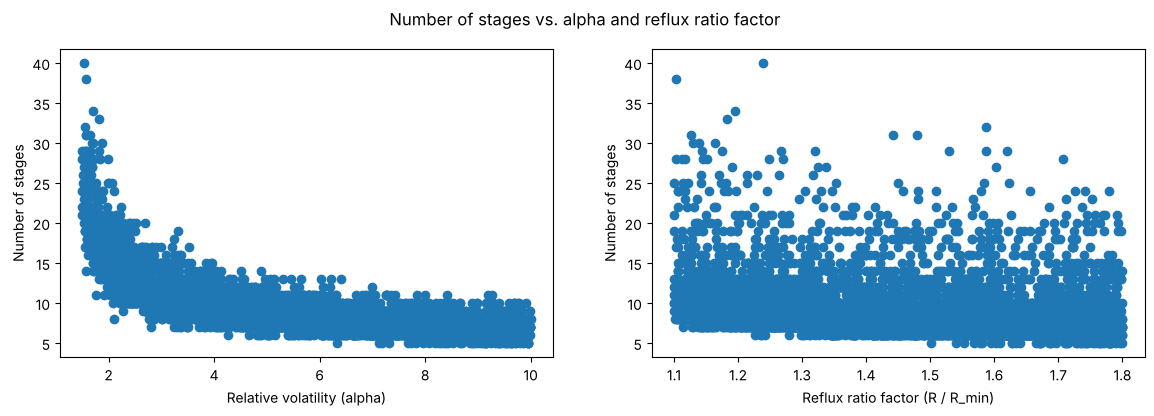

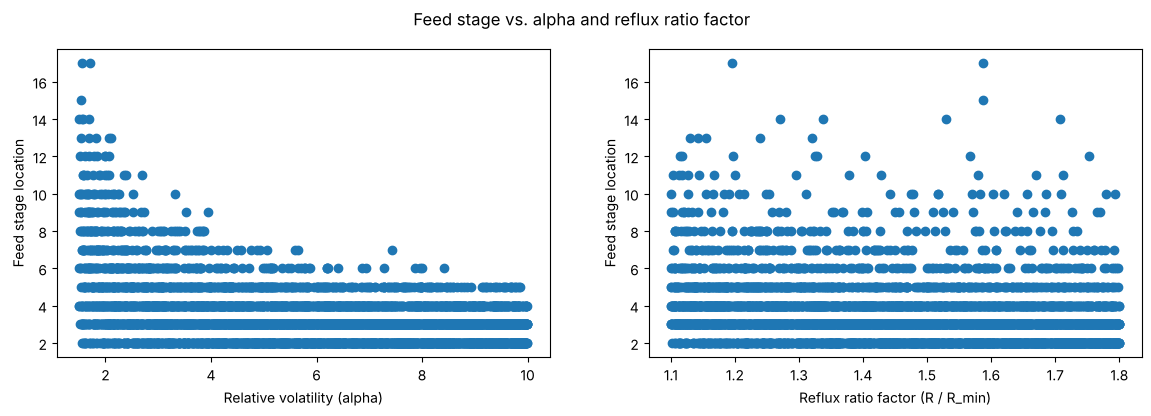

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].scatter(df.alpha, df.stage_numbers)
ax[0].set_xlabel("Relative volatility (alpha)")
ax[0].set_ylabel("Number of stages")
ax[1].scatter(df.R_factor, df.stage_numbers)
ax[1].set_xlabel("Reflux ratio factor (R / R_min)")
ax[1].set_ylabel("Number of stages")
plt.suptitle("Number of stages vs. alpha and reflux ratio factor")
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].scatter(df.alpha, df.feed_stage)
ax[0].set_xlabel("Relative volatility (alpha)")
ax[0].set_ylabel("Feed stage location")
ax[1].scatter(df.R_factor, df.feed_stage)
ax[1].set_xlabel("Reflux ratio factor (R / R_min)")
ax[1].set_ylabel("Feed stage location")
plt.suptitle("Feed stage vs. alpha and reflux ratio factor")
plt.show()

In [7]:
df[["alpha", "R", "xF", "xD", "xB", "stage_numbers", "feed_stage"]].corr()

,alpha,R,xF,xD,xB,stage_numbers,feed_stage
alpha,1.000000,-0.525926,-0.011971,0.373458,0.004992,-0.716603,-0.407974
R,-0.525926,1.000000,-0.261386,-0.089301,0.002304,0.647332,0.714646
xF,-0.011971,-0.261386,1.000000,0.565331,-0.018692,0.046052,0.036249
xD,0.373458,-0.089301,0.565331,1.000000,-0.000262,-0.211878,0.279415
xB,0.004992,0.002304,-0.018692,-0.000262,1.000000,-0.218874,0.014936
stage_numbers,-0.716603,0.647332,0.046052,-0.211878,-0.218874,1.000000,0.687397
feed_stage,-0.407974,0.714646,0.036249,0.279415,0.014936,0.687397,1.000000


## 5. Feature engineering

Add inverse terms (`1/R`, `1/alpha`) and their product, then build the feature matrix `X` and the two targets.

**Note:** `R`/`inv_R` and `alpha`/`inv_alpha` are redundant pairs (each is the reciprocal of the other). That
doesn't hurt prediction, but it makes individual coefficients unreliable to interpret in isolation.

In [8]:
df["inv_R"] = 1 / df["R"]
df["inv_alpha"] = 1 / df["alpha"]
df["interactions"] = df["inv_R"] * df["inv_alpha"]

feature_names = ["alpha", "R", "xF", "xD", "xB", "inv_R", "inv_alpha", "interactions"]
X = df[feature_names].to_numpy()
y_stage_num = df["stage_numbers"].to_numpy()
y_feed_stage = df["feed_stage"].to_numpy()

## 6. Train/test split

One split for both targets, so both models are trained and tested on exactly the same rows.
80% train, 20% test. The scaler is **fit on the training data only**, then applied to the test data.

In [9]:
X_train, X_test, y1_train, y1_test, y2_train, y2_test = train_test_split(
    X, y_stage_num, y_feed_stage, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_norm = scaler.fit_transform(X_train)   # fit on train only
X_test_norm = scaler.transform(X_test)         # transform only, never fit on test

print("Train:", X_train_norm.shape, " Test:", X_test_norm.shape)

Train: (4000, 8)  Test: (1000, 8)


## 7. Model 1: number of stages

Plots to read:
- **Predicted vs. actual:** points on the red dashed line mean perfect predictions.
- **Residuals:** should scatter randomly around 0. A curved or sign-flipping pattern means the model shape is wrong.

Train R2: 0.837910030045677
Test  R2: 0.8387374056707555
Test RMSE: 1.498116149953991


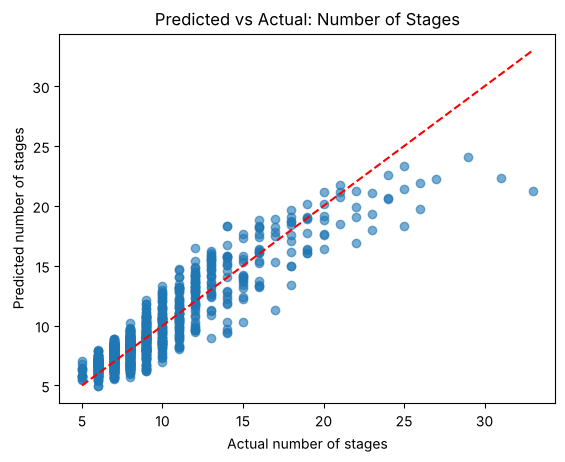

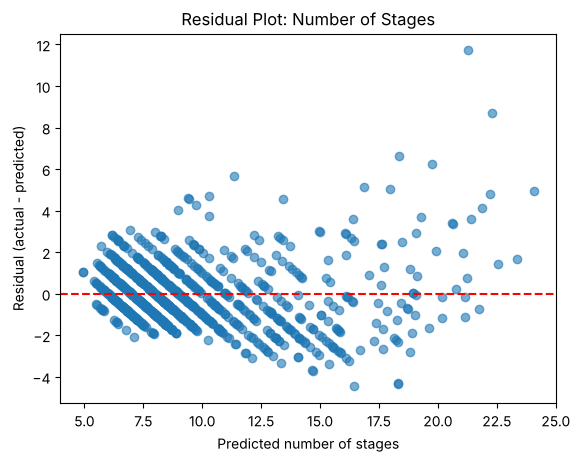

In [10]:
model1 = LinearRegression()
model1.fit(X_train_norm, y1_train)
y1_pred = model1.predict(X_test_norm)

print("Train R2:", model1.score(X_train_norm, y1_train))
print("Test  R2:", r2_score(y1_test, y1_pred))
print("Test RMSE:", np.sqrt(mean_squared_error(y1_test, y1_pred)))

plt.scatter(y1_test, y1_pred, alpha=0.6)
plt.plot([y1_test.min(), y1_test.max()], [y1_test.min(), y1_test.max()], "r--")
plt.xlabel("Actual number of stages")
plt.ylabel("Predicted number of stages")
plt.title("Predicted vs Actual: Number of Stages")
plt.show()

residuals1 = y1_test - y1_pred
plt.scatter(y1_pred, residuals1, alpha=0.6)
plt.axhline(0, color="r", linestyle="--")
plt.xlabel("Predicted number of stages")
plt.ylabel("Residual (actual - predicted)")
plt.title("Residual Plot: Number of Stages")
plt.show()

## 8. Model 2: feed stage location

Train R2: 0.6946824797394701
Test  R2: 0.7082443764319015
Test RMSE: 0.8661646062338739


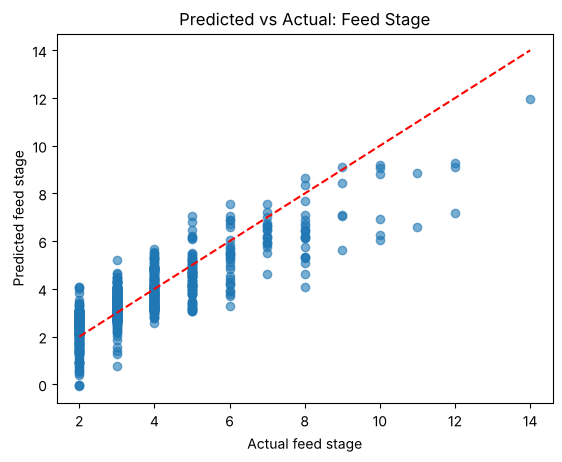

In [11]:
model2 = LinearRegression()
model2.fit(X_train_norm, y2_train)
y2_pred = model2.predict(X_test_norm)

print("Train R2:", model2.score(X_train_norm, y2_train))
print("Test  R2:", r2_score(y2_test, y2_pred))
print("Test RMSE:", np.sqrt(mean_squared_error(y2_test, y2_pred)))

plt.scatter(y2_test, y2_pred, alpha=0.6)
plt.plot([y2_test.min(), y2_test.max()], [y2_test.min(), y2_test.max()], "r--")
plt.xlabel("Actual feed stage")
plt.ylabel("Predicted feed stage")
plt.title("Predicted vs Actual: Feed Stage")
plt.show()

## 9. Results summary

All numbers in one table, from this single run. Metrics are on the 20% held-out test set unless labelled train.
`RMSE / std` is the typical error as a share of how much the target varies (smaller is better).

In [12]:
results = pd.DataFrame({
    "Target": ["Number of stages", "Feed stage"],
    "Train R2": [model1.score(X_train_norm, y1_train), model2.score(X_train_norm, y2_train)],
    "Test R2": [r2_score(y1_test, y1_pred), r2_score(y2_test, y2_pred)],
    "Test RMSE": [np.sqrt(mean_squared_error(y1_test, y1_pred)),
                  np.sqrt(mean_squared_error(y2_test, y2_pred))],
    "Target std": [y1_test.std(), y2_test.std()],
})
results["RMSE / std"] = results["Test RMSE"] / results["Target std"]
results.round(2)

,Target,Train R2,Test R2,Test RMSE,Target std,RMSE / std
0,Number of stages,0.84,0.84,1.50,3.73,0.40
1,Feed stage,0.69,0.71,0.87,1.60,0.54


## 10. Error inspection

Aggregate R² hides *where* the model fails. For each actual stage count, this shows the lowest and highest
prediction and how many test rows there are. Only groups with at least 20 rows are shown, so that a single
row can't mislead.

In [13]:
test_df = pd.DataFrame(X_test, columns=feature_names)
test_df["actual"] = y1_test
test_df["predicted"] = y1_pred

spread = test_df.groupby("actual")["predicted"].agg(["min", "max", "count"])
spread[spread["count"] >= 20].round(1)

,min,max,count
actual,,,
6,4.9,8.0,112
7,5.5,8.9,199
8,5.7,10.2,209
9,6.2,12.1,137
10,7.0,13.4,76
11,8.0,14.7,60
12,9.4,16.5,51
13,9.0,16.2,31
14,9.4,18.3,23


## 11. What I learned / next steps

- **Train R² and test R² are nearly equal** for both targets. A big train > test gap would mean overfitting;
  equal and mediocre scores suggest **underfitting (high bias)**: a straight-line model is too simple for a curved relationship.
- The feed stage has a **narrower spread** than the stage count, so the same size of error is a bigger share of it
  (higher `RMSE / std`). This is a hypothesis for the lower R², not a proven cause.

**Next:** polynomial features + Ridge, neural network, Random Forest, XGBoost, and a comparison of all models.